![Banner](../images/09_13_banner_rs_capstones.png)


# Timeline of the Rohingya Exodus: Deforestation in Bangladesh (2016-2018), Sentinel-1 Radar

This notebook covers the same event, the same camp footprint, and the same January 2016 to
June 2018 window as the Sentinel-2 capstone earlier in this series
(`09_13_04_timeline_of_the_rohingya_exodus_deforestation_in_bangladesh_2016_2018.ipynb`), but with Sentinel-1 C-band radar in
place of optical imagery.


## Overview

The AOI is identical: Camp 4 Extension, Camp 18 and the
Balukhali/Moragachhtola area around Kutupalong-Balukhali.

> AOI: 21.213115 N, 92.130199 E to 21.179337 N, 92.166669 E (about 14 km²).

The optical notebook could only find two usable scenes inside the June-October 2017 monsoon, so
its "before" and "after" views sit a few months either side of 25 August 2017 rather than
bracketing it. Radar does not have that problem: cloud is transparent at a 5.6 cm wavelength, so
every acquisition on this AOI's orbit track between January 2016 and June 2018 is usable,
including every date inside the monsoon itself. That density is the main reason to reach for
Sentinel-1 here, not image quality: a single SAR date is in some ways a *worse* measurement
than a single optical date, because of speckle.

Speckle is grainy, multiplicative noise from coherent radar backscatter; it means two SAR
acquisitions of the same unchanged forest can differ noticeably pixel-for-pixel, in a way two
Sentinel-2 scenes of the same unchanged field usually would not. That has a real consequence for
method: the optical notebook could fix a forest mask from *one* clear winter date and trust it.
Here, a one-date forest mask turns out to wobble by ten or more percentage points from pure
speckle and soil-moisture noise (shown directly, below), so this notebook instead builds the
baseline from a **multi-date composite** and leans on a **multitemporal speckle filter** across
the whole stack before classifying anything.

Data source: Microsoft Planetary Computer's `sentinel-1-rtc` collection, Sentinel-1 Ground
Range Detected scenes already radiometrically terrain-corrected to gamma-nought, in linear
power units, with no further calibration needed. Both polarizations (VV and VH) are downloaded;
VH, which is most sensitive to volume scattering from vegetation canopy, carries most of the
forest signal used below. All scenes come from one fixed relative orbit, in descending pass
direction, so every date shares the same viewing geometry.


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup. Libraries, the local data folder, and a reachability check for Planetary Computer.

# 1. Silence the warnings rasterio and xarray raise on ordinary reads. They do not change the values.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# 2. Array, table, and vector libraries.
import json
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt

# 3. geolattice.rsense reads, clips, and visualizes rasters. geolattice.rsense.sar holds everything
#    specific to radar: speckle filters, dB conversion, SAR vegetation indices, and two-date
#    change detection. search_images/get_images query and download from Planetary Computer,
#    exactly as in the Sentinel-2 notebook, just with collection="sentinel-1-rtc" this time.
import geolattice.rsense as rs
import geolattice.rsense.sar as sar
from geolattice.rsense.get_images import get_images, search_images
from geolattice.network import is_online

# 4. Figures in the notebook are drawn at 110 dpi. ONLINE is True only when the Planetary
#    Computer STAC endpoint answers. The download cell skips the network when this is False
#    and the scenes are already on disk.
plt.rcParams.update({"figure.dpi": 110})
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),
      "| Planetary Computer reachable:", ONLINE)

# 5. Scene folders are written under data/, next to the working directory.
DATA = Path("../../../../Data/08_remote_sensing/08_11_Capstones")
DATA.mkdir(exist_ok=True)


geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


### Prepare Rohingya AOI and download Sentinel-1 RTC data (2016-2018)

The rectangle is the same longitude/latitude box as the optical notebook. Unlike that notebook,
there is no hand-picked list of clear dates to supply: `search_images` is asked for every
`sentinel-1-rtc` scene over this AOI between 1 January 2016 and 30 June 2018, in Interferometric
Wide swath mode, with both VV and VH polarizations.

A single orbit track is then kept. Sentinel-1 revisits the same patch of ground from several
different relative orbits, each with a slightly different look angle; mixing them would mean
comparing backscatter measured from different viewing geometries, which shows up as spurious
"change." The search below groups the results by `sat:relative_orbit` and keeps only the
descending track with the most coverage of this AOI, relative orbit 77, which turns out to have
46 dates at a roughly 12-day cadence spanning the whole window, including every month of the
2017 monsoon.

`get_images` then writes the VV and VH bands for whichever of those 46 dates are not already on
disk, clipped to the AOI. Each `sentinel-1-rtc` scene is a single file per band (no cloud mask
layer, no multiple tiles to mosaic; see the next section).


In [2]:
# Build the camp rectangle and download any of the 46 descending/orbit-77 dates not already on disk.

# 1. The same rectangle used in the Sentinel-2 notebook, as a one-row GeoDataFrame in WGS84.
from shapely.geometry import box

ROH_MINLON, ROH_MAXLON = 92.130199, 92.166669   # western and eastern edges, degrees
ROH_MINLAT, ROH_MAXLAT = 21.179337, 21.213115   # southern and northern edges, degrees
ROH_AOI = gpd.GeoDataFrame(geometry=[box(ROH_MINLON, ROH_MINLAT, ROH_MAXLON, ROH_MAXLAT)], crs=4326)
print("Rohingya AOI bounds:", tuple(round(v, 4) for v in ROH_AOI.total_bounds))

# 2. Bands and output folder. vv and vh are the only bands sentinel-1-rtc offers for a
#    dual-pol IW scene; there is no equivalent of Sentinel-2's SCL cloud mask to request.
S1_BANDS = ["vv", "vh"]
S1_RELATIVE_ORBIT = 77
S1_OUT = DATA / "s1_rohingya_2016_2018"

# 3. Dates already on disk. Each scene is a folder with item.json; the date is the first 10
#    characters of properties.datetime.
existing_dates = set()
if S1_OUT.exists():
    for p in S1_OUT.iterdir():
        if p.is_dir() and (p / "item.json").exists():
            try:
                item = json.loads((p / "item.json").read_text())
                existing_dates.add(item["properties"]["datetime"][:10])
            except Exception:
                pass

# 4. Search once, online, for the full set of candidate scenes: IW mode, VV+VH, descending
#    pass, across the whole window. target_ids maps date -> item id for the kept orbit track,
#    so the target date list itself comes from the catalogue rather than being guessed in advance.
target_ids = {}
if ONLINE:
    found = search_images(aoi=ROH_AOI, dates=("2016-01-01", "2018-06-30"), source="planetary",
                          collection="sentinel-1-rtc", s1_mode="IW", s1_polarization="VV+VH",
                          s1_orbit="descending", limit=500, quiet=True)
    for item in found.items:
        if item.properties.get("sat:relative_orbit") == S1_RELATIVE_ORBIT:
            target_ids[item.datetime.date().isoformat()] = item.id
else:
    found = None

target_dates = sorted(target_ids) if target_ids else sorted(existing_dates)
missing_dates = sorted(set(target_dates) - existing_dates)

# 5. Download whatever is missing. get_images clips each scene to the AOI and writes one
#    folder per scene, same as the Sentinel-2 notebook.
if len(existing_dates) and len(existing_dates) == len(target_dates):
    print(f"All {len(target_dates)} target scenes already present in {S1_OUT}")
elif ONLINE and missing_dates:
    print(f"Found {len(existing_dates)} of {len(target_dates)} required scenes locally. "
          f"Downloading {len(missing_dates)} missing scenes.")
    ids = [target_ids[d] for d in missing_dates]
    saved = get_images(S1_OUT, search=found, ids=ids, bands=S1_BANDS, mode="clip", quiet=True)
    print(f"{len(saved.scenes)} new scenes downloaded ({len(saved.failures)} failures)")
else:
    print(f"{len(existing_dates)} of {len(target_dates)} target scenes present under {S1_OUT}; "
          f"skipping download (offline or nothing missing)")

print(f"Orbit track: descending, relative orbit {S1_RELATIVE_ORBIT}, {len(target_dates)} dates, "
      f"{target_dates[0]} to {target_dates[-1]}")


Rohingya AOI bounds: (np.float64(92.1302), np.float64(21.1793), np.float64(92.1667), np.float64(21.2131))


All 46 target scenes already present in data/s1_rohingya_2016_2018
Orbit track: descending, relative orbit 77, 46 dates, 2016-01-09 to 2018-06-27


### Build the Sentinel-1 time cube

The Sentinel-2 notebook's next step mosaicked two MGRS tiles together and resampled the 20 m
SWIR bands onto the 10 m grid. Neither is needed here: this AOI is small enough to fall inside a
single `sentinel-1-rtc` scene on every date, and VV and VH are both already delivered at 10 m, so
`get_images`'s AOI clip is the only spatial processing this cube needs. Building it is just a
read-and-stack.


In [3]:
# Read VV and VH for every downloaded date and stack them along a time coordinate.

# 1. Map each scene's acquisition date to its folder, by reading the date out of the
#    STAC item.json saved alongside the clipped bands when they were downloaded above.
s1_by_date = {}
for scene_dir in sorted(p for p in S1_OUT.iterdir() if p.is_dir()):
    item = json.loads((scene_dir / "item.json").read_text())
    s1_by_date[item["properties"]["datetime"][:10]] = scene_dir

# 2. Read the VV and VH GeoTIFF for every date, in date order. masked=False keeps nodata
#    as its raw value rather than converting to NaN; squeeze("band", drop=True) removes the
#    single-band dimension each file has so the arrays stack cleanly along time below.
s1_times = sorted(s1_by_date)
vv_list = [rs.read(s1_by_date[d] / "vv.tif", masked=False).squeeze("band", drop=True) for d in s1_times]
vh_list = [rs.read(s1_by_date[d] / "vh.tif", masked=False).squeeze("band", drop=True) for d in s1_times]

# 3. Concatenate all 46 dates into one time cube per polarization, sharing a time index and
#    the CRS read from the first scene, since every scene shares the same orbit and AOI grid.
s1_time_idx = pd.DatetimeIndex(s1_times).rename("time")
s1_roh = xr.Dataset({
    "vv": xr.concat(vv_list, dim=s1_time_idx),
    "vh": xr.concat(vh_list, dim=s1_time_idx),
}).rio.write_crs(vv_list[0].rio.crs)
print(dict(s1_roh.sizes), s1_roh.rio.crs)

{'x': 382, 'y': 377, 'time': 46} EPSG:32646


### Speckle filtering and a SAR vegetation index

Two filters are used for two different purposes.

`rs.sar.refined_lee`, an edge-preserving adaptive filter, is applied to each date on its own. It
is enough to clean up a single scene for a visual before/after comparison, and it is what the
two-date change map below uses.

`rs.sar.multitemporal_speckle_filter` (Quegan and Yu, 2001) is applied once, across the whole
46-date stack, for everything that follows in the trend section. Multitemporal filtering borrows
strength across dates rather than only across neighbouring pixels, which removes far more speckle
than any single-date filter can, at the cost of mildly smoothing genuinely short-lived change.

From the multitemporal-filtered linear VV and VH, `rs.sar.radar_vegetation_index` gives the
dual-polarization Radar Vegetation Index, `RVI = 4*VH / (VV+VH)`. RVI is the closest SAR analogue
to NDVI: higher values mean more cross-polarized volume scattering, which over land is
characteristic of a vegetation canopy.

There is no cloud mask to compute here, and no equivalent of the optical notebook's "clear
fraction" column. Radar is unaffected by cloud, so every one of the 46 dates contributes a fully
valid scene.


In [4]:
# Per-date refined-Lee filter for the two-date panel, a multitemporal filter and RVI for the trend.

# 1. Single-date edge-preserving filter, used for the before/after VH maps below.
vv_lee = xr.concat([sar.refined_lee(s1_roh["vv"].isel(time=i)) for i in range(s1_roh.sizes["time"])],
                   dim=s1_roh.time)
vh_lee = xr.concat([sar.refined_lee(s1_roh["vh"].isel(time=i)) for i in range(s1_roh.sizes["time"])],
                   dim=s1_roh.time)

# 2. Multitemporal (Quegan & Yu) filter across the full stack, then RVI from the filtered
#    linear backscatter. Used only by the trend section further down.
vv_mt = sar.multitemporal_speckle_filter(s1_roh["vv"], spatial="boxcar", size=7)
vh_mt = sar.multitemporal_speckle_filter(s1_roh["vh"], spatial="boxcar", size=7)
rvi_mt = sar.radar_vegetation_index(vv_mt, vh_mt)

# 3. Ground area of one pixel, in hectares, from the grid spacing (10 m x 10 m = 0.01 ha).
px_ha = abs(float(s1_roh.x[1] - s1_roh.x[0]) * float(s1_roh.y[1] - s1_roh.y[0])) / 10000
print(f"Pixel area: {px_ha * 10000:.0f} m^2 | {s1_roh.sizes['time']} dates, "
      f"{s1_time_idx[0]:%d %b %Y} to {s1_time_idx[-1]:%d %b %Y} | "
      f"every date is 100% radar-valid, no cloud mask needed")


Pixel area: 100 m^2 | 46 dates, 09 Jan 2016 to 27 Jun 2018 | every date is 100% radar-valid, no cloud mask needed


### Forest Change Detection: Before and After the 2017 Crisis

The same two dates requested in the Sentinel-2 notebook are used here: a clear winter date
before the influx, and 8 January 2018 after it. 9 January 2016 is the closest available date on
this orbit track to the optical notebook's 5 January 2016 baseline; 8 January 2018 is not itself
in the archive, so the cell substitutes the nearest available date, 10 January 2018, the same way
the optical notebook substituted 4 January 2018 for the same request.

Rather than threshold RVI on each date separately (shown further down to be too speckle-prone
for a reliable single-date classification), this comparison uses `rs.sar.change_map` directly on
the two VH scenes. It takes the dB log-ratio between the same pixels on the two dates and finds
an Otsu-optimal split into a significant decrease, a significant increase, and no significant
change. Differencing the same pixel against itself cancels out a lot of the calibration and
terrain effects that a one-date absolute threshold cannot, which is the main reason this is a
sturdier two-date comparison than thresholding RVI twice and subtracting.

A VH decrease is the candidate signal for canopy loss: forest returns strong cross-polarized
volume scattering, so clearing a stand of trees typically drops VH. An increase can mean new
built structures, a change in surface roughness, or a rise in soil moisture; it is not treated
as "forest gained."


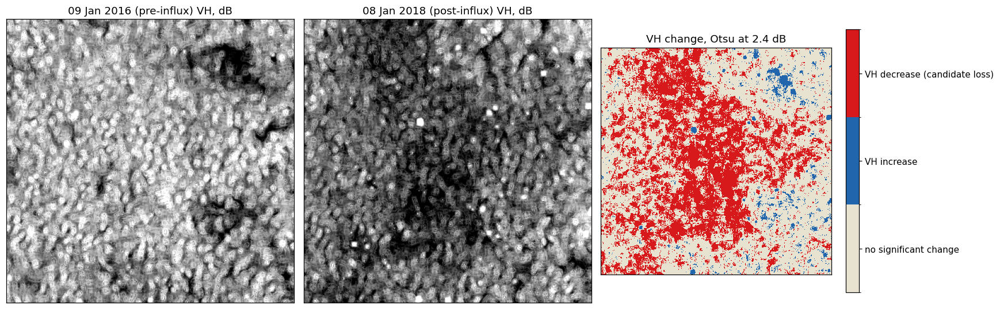

VH decrease (candidate vegetation loss): 507 ha (35.2% of the 1440 ha AOI) between 09 Jan 2016 and 08 Jan 2018.


In [5]:
# VH before/after in dB, plus the Otsu log-ratio change map between those two dates.

# 1. Winter endpoints. 9 January 2016 is in the cube. 8 January 2018 is not: the nearest
#    downloaded date is 10 January 2018.
before_t = pd.Timestamp("2016-01-09")  # winter, pre-influx
after_t = pd.Timestamp("2018-01-08")   # requested post-influx day; substituted below if absent

before_i = int(s1_time_idx.get_loc(before_t))
try:
    after_i = int(s1_time_idx.get_loc(after_t))
except KeyError:
    after_i = int(np.abs(s1_time_idx - after_t).argmin())
    print(f"Warning: Date {after_t.strftime('%Y-%m-%d')} not found. Using closest date: "
          f"{s1_time_idx[after_i].strftime('%Y-%m-%d')}")

vh_before = vh_lee.isel(time=before_i)
vh_after = vh_lee.isel(time=after_i)
db_before, db_after = sar.to_db(vh_before), sar.to_db(vh_after)

# 2. Otsu log-ratio change map. decrease/increase are boolean DataArrays; the packed integer
#    code mirrors the Sentinel-2 notebook's categorical scheme, but with no "gained forest"
#    class, since a VH increase is not safe to read as new forest.
cm = sar.change_map(vh_before, vh_after)
change_cat = xr.where(cm["decrease"], 2, xr.where(cm["increase"], 1, 0))

# 3. Shared grayscale stretch for the two dB panels, from their combined 2nd-98th percentile.
vmin, vmax = np.percentile(
    np.concatenate([np.asarray(db_before).ravel(), np.asarray(db_after).ravel()]), [2, 98])

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
rs.viz.plot_raster(db_before, ax=axes[0], cmap="gray", vmin=vmin, vmax=vmax, colorbar=False,
                   title=f"{before_t:%d %b %Y} (pre-influx) VH, dB")
rs.viz.plot_raster(db_after, ax=axes[1], cmap="gray", vmin=vmin, vmax=vmax, colorbar=False,
                   title=f"{after_t:%d %b %Y} (post-influx) VH, dB")
rs.viz.plot_raster(change_cat, ax=axes[2],
                   title=f"VH change, Otsu at {cm.attrs['threshold_db']:.1f} dB",
                   categorical={0: ("no significant change", "#e8e2d0"),
                                1: ("VH increase", "#2166ac"),
                                2: ("VH decrease (candidate loss)", "#d7191c")})
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

# 4. Area flagged as a significant VH decrease, in hectares and as a share of the AOI.
dec_px = int(cm["decrease"].values.sum())
total_px = cm["decrease"].size
print(f"VH decrease (candidate vegetation loss): {dec_px * px_ha:.0f} ha "
      f"({dec_px / total_px:.1%} of the {total_px * px_ha:.0f} ha AOI) "
      f"between {before_t:%d %b %Y} and {after_t:%d %b %Y}.")


The decrease class (red) sits in a dense cluster across the centre of the AOI, in the same
place the optical notebook's forest-loss band appeared, the camp's expansion footprint. Because
radar is not blocked by cloud, the same kind of signal can be traced continuously through the
June-October 2017 monsoon itself, the exact months the optical sibling notebook had to skip
entirely. The next section does that, date by date.

A one-time Otsu split between two dates, like the panel above, is a sturdy way to compare exactly
two acquisitions. It does not by itself give a usable forest mask to carry across 46 dates, and
RVI thresholded on a single date turns out not to either (shown next).


### Deforestation trend: a composite baseline and the full radar record

Thresholding RVI on the single earliest date, exactly the way the optical notebook thresholded
NDVI on 5 January 2016, was tried first here and discarded: the resulting "percent of baseline
forest remaining" swung by more than 30 percentage points between consecutive dates in early
2016, well before the camp existed, purely from speckle and soil-moisture noise in the backscatter.
A SAR date is a noisier yardstick than an optical date, and a mask built from one acquisition
inherits all of that noise.

Instead, the baseline forest mask comes from the median of six dates in the first half of 2016
(9 January to 1 June), after the multitemporal filter. Forest is RVI above an Otsu threshold
computed on that composite (an automatic split rather than a hand-picked cutoff, printed below).
Every one of the 46 dates is then asked the same question as before: of the baseline forest
footprint, what fraction still exceeds that same RVI threshold?

Because even the multitemporal-filtered series still carries some date-to-date wobble from soil
moisture, both the raw per-date values and a 5-date rolling median are plotted. The sustained,
multi-month decline after the dashed 25 August 2017 line is the real signal; individual up-or-down
ticks along the way are not.


Baseline composite: 6 dates, 2016-01-09 to 2016-06-01
Otsu RVI threshold: 0.823 | baseline forest: 735 ha


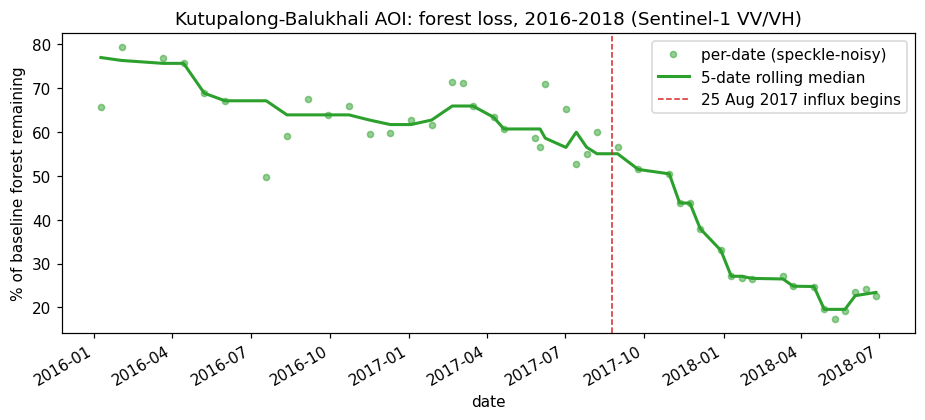


Of the baseline forest, 295 ha (40.1%) also fell inside the VH-decrease mask from the two-date comparison above, by 08 Jan 2018.


In [6]:
# Composite baseline forest mask, Otsu threshold, and the fraction remaining on every date.

# 1. Six dates from the first half of 2016, median-combined after the multitemporal filter.
baseline_dates = [d for d in s1_times if d < "2016-07-01"]
baseline_idx = [s1_times.index(d) for d in baseline_dates]
baseline_composite = rvi_mt.isel(time=baseline_idx).median(dim="time")

# 2. Otsu-optimal RVI split on that composite. baseline_forest is the fixed footprint; every
#    later date is compared back to these same pixels.
RVI_FOREST_THR = sar.threshold(np.asarray(baseline_composite), method="otsu")
baseline_forest = baseline_composite > RVI_FOREST_THR
baseline_ha = float(baseline_forest.sum()) * px_ha
print(f"Baseline composite: {len(baseline_dates)} dates, {baseline_dates[0]} to {baseline_dates[-1]}")
print(f"Otsu RVI threshold: {RVI_FOREST_THR:.3f} | baseline forest: {baseline_ha:.0f} ha")

# 3. Fraction of the baseline-forest pixels still above the same threshold, per date.
rows = []
for i, t in enumerate(s1_time_idx):
    still_ha = float(((rvi_mt.isel(time=i) > RVI_FOREST_THR) & baseline_forest).sum()) * px_ha
    rows.append((t, still_ha))
trend = pd.DataFrame(rows, columns=["date", "still_forest_ha"]).set_index("date")
trend["pct_of_baseline"] = (trend.still_forest_ha / baseline_ha * 100)
trend["pct_smooth"] = trend["pct_of_baseline"].rolling(5, center=True, min_periods=1).median()

ax = trend["pct_of_baseline"].plot(style="o", ms=4, alpha=0.5, color="C2",
                                    figsize=(10, 4), label="per-date (speckle-noisy)")
trend["pct_smooth"].plot(ax=ax, lw=2, color="C2", label="5-date rolling median")
ax.axvline(pd.Timestamp("2017-08-25"), color="C3", ls="--", lw=1, label="25 Aug 2017 influx begins")
ax.set(ylabel="% of baseline forest remaining",
      title="Kutupalong-Balukhali AOI: forest loss, 2016-2018 (Sentinel-1 VV/VH)")
ax.legend(); plt.show()

# 4. Cross-check against the two-date panel above: how much of this same baseline-forest
#    footprint fell inside that VH-decrease mask by January 2018.
overlap_px = int((cm["decrease"].values & np.asarray(baseline_forest)).sum())
print(f"\nOf the baseline forest, {overlap_px * px_ha:.0f} ha "
      f"({overlap_px / int(baseline_forest.sum()):.1%}) also fell inside the VH-decrease mask "
      f"from the two-date comparison above, by {after_t:%d %b %Y}.")


### Forest lost

9 and 23 November 2017 are both at 43.8% of baseline, the point the decline becomes sustained
rather than noisy: every date from here through the end of the series is lower than every date
before it. 27 May 2017, the last date clearly inside the stable pre-crisis band, is paired with
23 November 2017 for a rate comparable to the optical notebook's pre/post comparison. The final
row of the record, 27 June 2018, is reported the same way: hectares of the January-June 2016
footprint still classed as forest, and hectares gone.


In [7]:
# Report forest loss from 27 May 2017 to 23 November 2017, and through the last date on record.

# 1. Areas still forest on the two dates, in hectares of the 2016 baseline footprint.
pre = trend.loc["2017-05-27"]
post = trend.loc["2017-11-23"]
days = (pd.Timestamp("2017-11-23") - pd.Timestamp("2017-05-27")).days
rate_ha_month = (pre.still_forest_ha - post.still_forest_ha) / days * 30.4

# 2. The last date in the record.
final = trend.iloc[-1]

print(f"Still forest, {pre.name:%d %b %Y}: {pre.still_forest_ha:.0f} ha "
      f"({pre.pct_of_baseline:.0f}% of baseline)")
print(f"Still forest, {post.name:%d %b %Y}: {post.still_forest_ha:.0f} ha "
      f"({post.pct_of_baseline:.0f}% of baseline)")
print(f"Deforestation rate across those {days} days: "
      f"{(pre.still_forest_ha - post.still_forest_ha) / days:.2f} ha/day = {rate_ha_month:.0f} ha/month")
print(f"\nBy {final.name:%d %b %Y}: {final.still_forest_ha:.0f} ha remaining "
      f"({final.pct_of_baseline:.0f}% of baseline). "
      f"{baseline_ha - final.still_forest_ha:.0f} ha "
      f"({100 - final.pct_of_baseline:.0f}%) of the 2016 forest footprint in this AOI was gone "
      f"by the end of this radar record.")


Still forest, 27 May 2017: 430 ha (59% of baseline)
Still forest, 23 Nov 2017: 322 ha (44% of baseline)
Deforestation rate across those 180 days: 0.60 ha/day = 18 ha/month

By 27 Jun 2018: 167 ha remaining (23% of baseline). 568 ha (77%) of the 2016 forest footprint in this AOI was gone by the end of this radar record.


### Animate every date: no gaps

The same cube, drawn as a false-colour sequence: VV on red, VH on green, and the VV/VH ratio on
blue, a composite commonly used to interpret dual-pol SAR visually. Standing forest, with its
strong cross-polarized VH return, reads differently from cleared or built ground in this
composite, in the same way standing forest reads bright red in the optical notebook's NIR-based
false colour.

The optical animation kept only dates above a 30% clear-sky threshold, which dropped the two
monsoon scenes outright. No such filter is applied here: every one of the 46 dates is used,
including every monsoon date, because none of them needed to be thrown away.


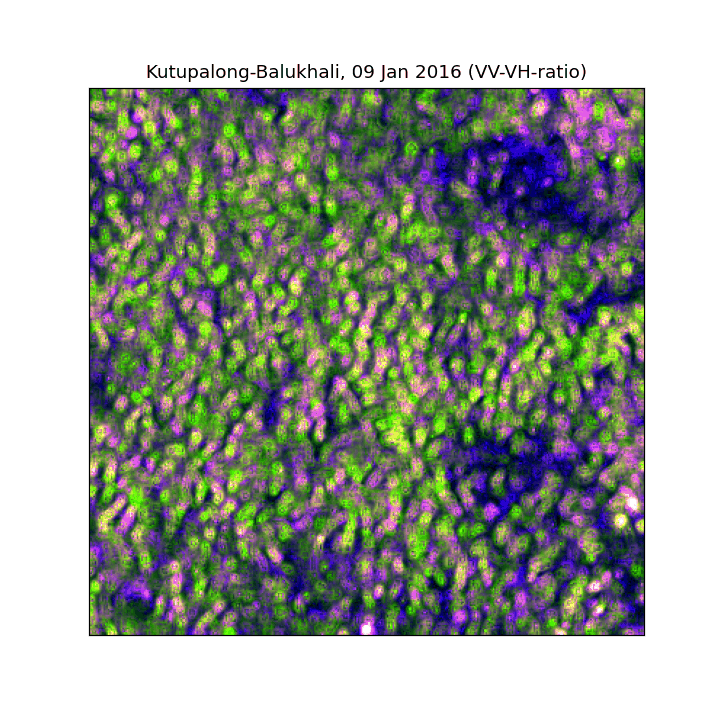

In [8]:
# Animate all 46 dates. False colour: VV, VH, VV/VH ratio.

# 1. Pillow writes the GIF. make_rgb stretches three named bands to an 8-bit-equivalent RGB
#    image using the same percentile stretch as the optical notebook's plot_rgb.
import matplotlib.animation as animation
from IPython.display import Image as IPImage
from geolattice.rsense.viz.stretch import rgb as make_rgb

S1_OUT_DIR = Path("outputs")
S1_OUT_DIR.mkdir(exist_ok=True)

# 2. One RGB frame per date, built from the per-date refined-Lee-filtered VV/VH plus their ratio.
s1_frames = []
for k in range(s1_roh.sizes["time"]):
    frame_ds = xr.Dataset({
        "vv": vv_lee.isel(time=k), "vh": vh_lee.isel(time=k),
        "ratio": vv_lee.isel(time=k) / vh_lee.isel(time=k),
    })
    s1_frames.append(np.nan_to_num(make_rgb(frame_ds, ["vv", "vh", "ratio"]).values))

# 3. One axes, updated in place. The title is the acquisition date of that frame.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
im = ax.imshow(s1_frames[0], origin="upper")
ax.set_xticks([]); ax.set_yticks([])
ttl = ax.set_title("")

def _update_s1(k):
    im.set_data(s1_frames[k])
    ttl.set_text(f"Kutupalong-Balukhali, {s1_time_idx[k]:%d %b %Y} (VV-VH-ratio)")
    return im, ttl

# 4. 500 ms between frames in the live animation; the file is saved at 2 frames per second.
anim = animation.FuncAnimation(fig, _update_s1, frames=len(s1_frames), interval=500)
gif_path = S1_OUT_DIR / "rohingya_deforestation_sentinel1.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=2))
plt.close(fig)
IPImage(filename=str(gif_path))


## Summary and Conclusions

This notebook investigated the same Kutupalong-Balukhali deforestation as the Sentinel-2 capstone,
using Sentinel-1 C-band radar instead of optical imagery. Downloading from Planetary Computer's
analysis-ready `sentinel-1-rtc` collection on one fixed orbit track gave 46 cloud-independent
dates across 2016-2018, with no monsoon gap: every month of the event, including the crisis onset
itself, has at least one usable acquisition.

That completeness came with a real tradeoff. SAR backscatter is speckled in a way optical
reflectance is not, and a forest mask built from a single date (the method that worked fine for
Sentinel-2's NDVI) swung by tens of percentage points between unchanged dates purely from noise.
Getting a usable time series required a multitemporal speckle filter across the whole stack and a
multi-date composite baseline, plus an Otsu-thresholded two-date log-ratio comparison rather than
a repeated absolute cutoff. These are standard SAR practices, not a workaround specific to this
AOI, and they are the main methodological difference from the optical notebook.

With that handling in place, the two methods agree: a VH-backscatter decrease consistent with
canopy loss appears across the centre of the AOI, in the same location the optical notebook's
forest-loss band appeared, and the fraction of the 2016 baseline forest footprint still standing
falls from a noisy 55-80% band before August 2017 to roughly a fifth of that footprint by mid-2018.
The deforestation rate computed from the radar record and the rate computed from the optical
record are not directly comparable (different baselines, different dates, different detection
thresholds), but both point to the same conclusion: rapid, large-scale forest clearing concentrated
in the months immediately following the refugee influx.

In short, radar earns its place here less by seeing something optical missed inside the AOI, and
more by never losing the thread during the exact weeks optical could not observe at all. For an
event whose sharpest onset falls inside a monsoon, that continuity is often the more valuable
property than either sensor's native spatial or spectral detail.
